# Machine Learning — Practical Session 1: Data Exploration and Preprocessing
**National Higher School of Advanced Technologies (ENSTA)**  
*Academic Year: 2026–2027*  

- **Student:** Hamadi Imededdine  
- **Level:** 4th Year Student (Artificial Intelligence Specialty)  
- **Group:** Group 1  
- **Course:** Machine Learning  

---

## Practical Objectives
This notebook implements an end-to-end exploratory and preprocessing workflow:
1. **Tabular Data Exploration & Partitioning:** Inspecting statistical structures, selecting sub-spaces, applying deep copying principles, and executing stratified train-test splits.
2. **Text Processing & Unstructured Corpora:** Stream-reading raw text with explicit encodings, exploring scikit-learn's 20 Newsgroups benchmark, and analyzing document length distributions and vocabulary.
3. **Missing Data Diagnostics & Imputation:** Mapping custom data entry markers to IEEE `NaN`, assessing missingness distributions with heatmaps, and applying domain-justified imputation strategies while avoiding data leakage.
4. **Feature Rescaling, Binarization & Categorical Encodings:** Comparing feature-wise scalers vs. sample-wise normalizers, binarizing numerical signals, and analyzing the mathematical implications of Ordinal vs. One-Hot encoding for nominal features.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    normalize,
    Binarizer,
    OrdinalEncoder,
    OneHotEncoder,
    LabelEncoder
)

# Plotting settings
%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_theme(style="ticks", palette="crest")
plt.rcParams.update({'figure.autolayout': True, 'font.sans-serif': 'DejaVu Sans', 'font.size': 10})

DATA_PATH = "data"


---
## Exercise 1 — Exploring a Tabular Dataset and Creating Data Splits
**Dataset:** `Iris_Dataset.csv`

The Iris dataset is a benchmark multivariate dataset consisting of 150 observations across 3 flower species (*Iris-setosa*, *Iris-versicolor*, *Iris-virginica*), with 4 morphological measurements in centimeters.


In [2]:
# 1. Load CSV into DataFrame named D
iris_file = os.path.join(DATA_PATH, "Iris_Dataset.csv")
D = pd.read_csv(iris_file)

# 2. Structural & Statistical Inspection
print(">>> Structural Info:")
D.info()

print(f"\n>>> Dimensions: {D.shape[0]} instances, {D.shape[1]} attributes")
print(f">>> Column Names: {list(D.columns)}")

print("\n>>> First 5 Observations:")
display(D.head())

print("\n>>> Descriptive Statistics:")
display(D.describe().T.round(3))


>>> Structural Info:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB

>>> Dimensions: 150 instances, 5 attributes
>>> Column Names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

>>> First 5 Observations:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



>>> Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.054,0.434,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.759,1.764,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199,0.763,0.1,0.3,1.30,1.8,2.5


### Structural & Statistical Commentary:
- `info()`: Confirms memory allocation (~7.9 KB) and that all 150 entries in all 5 columns are non-null. The 4 measurement features are continuous floats (`float64`), while the ground-truth target `species` is of type `object` (string).
- `shape`: $(150, 5)$, denoting a design matrix $\mathbf{X} \in \mathbb{R}^{150 \times 4}$ with an accompanying class vector $\mathbf{y} \in \mathcal{Y}^{150}$.
- `columns`: Confirms feature taxonomy: `sepal_length`, `sepal_width`, `petal_length`, `petal_width`, and `species`.
- `head()`: Provides a sample verification showing physical measurements are positive values on the centimeter scale.
- `describe()`: Quantifies central tendency (mean, median) and dispersion (std, IQR). Note that `petal_length` has a high standard deviation ($\sigma = 1.764$) relative to its mean ($3.759$), reflecting significant separation between species, whereas `sepal_width` is tightly clustered ($\sigma = 0.434$).


In [3]:
# 3. Select features sepal_length and petal_width
sub_features = D[["sepal_length", "petal_width"]]

# 4. Display the first 20 observations
print(">>> First 20 observations of selected sub-features:")
display(sub_features.head(20))

# 5. Create a defensive copy
D_copy = D.copy()


>>> First 20 observations of selected sub-features:


,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


### Why is creating a copy essential?
1. **Preserving Ground Truth:** In data science pipelines, transformations (imputations, scalers, outlier clipping) mutate values. Retaining a clean reference copy `D` ensures reproducibility and prevents cascade errors without needing to re-read from disk.
2. **Avoiding Slice Reference Conflicts:** Operating on views or sliced DataFrames often triggers Pandas' `SettingWithCopyWarning`. A deep copy guarantees independent heap memory allocation.


In [4]:
# 6 & 7. Stratified Train-Test Split (80% Train, 20% Test)
X = D.drop(columns=["species"])
y = D["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Verification of sample sizes and class distributions
split_summary = pd.DataFrame({
    "Total Samples": [len(D), 1.0],
    "Train Set (80%)": [len(X_train), len(X_train) / len(D)],
    "Test Set (20%)": [len(X_test), len(X_test) / len(D)]
}, index=["Count", "Proportion"])
display(split_summary)

# Check class frequencies across splits
class_dist = pd.DataFrame({
    "Train Count": y_train.value_counts(),
    "Train %": y_train.value_counts(normalize=True) * 100,
    "Test Count": y_test.value_counts(),
    "Test %": y_test.value_counts(normalize=True) * 100
})
display(class_dist.round(2))


,Total Samples,Train Set (80%),Test Set (20%)
Count,150.0,120.0,30.0
Proportion,1.0,0.8,0.2


,Train Count,Train %,Test Count,Test %
species,,,,
Iris-setosa,40,33.33,10,33.33
Iris-virginica,40,33.33,10,33.33
Iris-versicolor,40,33.33,10,33.33


> ### Discussion: Why must the test set remain isolated until final evaluation?
> 
> The test set serves as an empirical surrogate for unseen real-world data to evaluate the model's true **generalization performance** $\mathcal{R}_{\text{gen}}(f)$.
> 
> If test set observations are accessed during preprocessing (e.g., computing global normalization parameters $\mu_{\text{dataset}}, \sigma_{\text{dataset}}$, imputing missing values via global medians, or performing feature selection), **data leakage** occurs. 
> 
> When data leaks:
> 1. The estimator inadvertently benefits from distributional priors of the test set during training.
> 2. Cross-validation and test metrics become overly optimistic (artificially high accuracy).
> 3. Once deployed in a production setting, the model suffers sharp degradation because it cannot rely on leaked future information.


---
## Exercise 2 — Exploring Text Data
**Files & Datasets:** `txt_file.txt` and Scikit-learn's `20 Newsgroups` corpus.


In [5]:
# 1 & 2. Open and read txt_file.txt with UTF-8 encoding
txt_path = os.path.join(DATA_PATH, "txt_file.txt")

with open(txt_path, mode="r", encoding="utf-8") as f:
    raw_lines = [line.rstrip("\r\n") for line in f]

for i, line in enumerate(raw_lines, start=1):
    print(f"Row {i:02d}: {line}")


Row 01: 0.50,0.20,0.84,0.01,c1
Row 02: 0.10,0.10,0.40,0.02,c2
Row 03: 0.15,0.10,0.45,0.03,c2
Row 04: 0.22,0.20,0.90,0.01,c1
Row 05: 0.25,0.20,0.87,0.01,c1
Row 06: 0.10,0.10,0.38,0.02,c2


In [6]:
# 3. Load 20 Newsgroups training dataset
newsgroups_data = fetch_20newsgroups(subset="train")

# 4. Display dimensions and semantics
n_documents = len(newsgroups_data.data)
n_labels = len(newsgroups_data.target)
n_classes = len(newsgroups_data.target_names)

print(f"Corpus size: {n_documents} documents | Label vector size: {n_labels}")
print(f"Number of topic categories: {n_classes}")

# 5. First document inspection
first_idx = newsgroups_data.target[0]
first_category = newsgroups_data.target_names[first_idx]
print(f"\nFirst sample label index: {first_idx} -> Topic: '{first_category}'")
print(f"First sample excerpt (first 300 characters):\n{'-'*50}")
print(newsgroups_data.data[0][:300].strip())
print(f"{'-'*50}")

# 6. Display class names
print("\nClass Names Index Mapping:")
for code, name in enumerate(newsgroups_data.target_names):
    print(f"  [{code:02d}] {name}")


Corpus size: 11314 documents | Label vector size: 11314
Number of topic categories: 20

First sample label index: 7 -> Topic: 'rec.autos'
First sample excerpt (first 300 characters):
--------------------------------------------------
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be
--------------------------------------------------

Class Names Index Mapping:
  [00] alt.atheism
  [01] comp.graphics
  [02] comp.os.ms-windows.misc
  [03] comp.sys.ibm.pc.hardware
  [04] comp.sys.mac.hardware
  [05] comp.windows.x
  [06] misc.forsale
  [07] rec.autos
  [08] rec.motorcycles
  [09] rec.sport.baseball
  [10] rec.sport.hockey
  [11] sci.crypt
  [12] sci.electronics
  [13] sci.med
  [14] sci.space
  [15] soc.religion.christian
  [16] talk.politics.

>>> Document Word Count Distribution:
  Min words:    14
  Max words:    11,821
  Mean words:   287.5
  Median words: 176.0


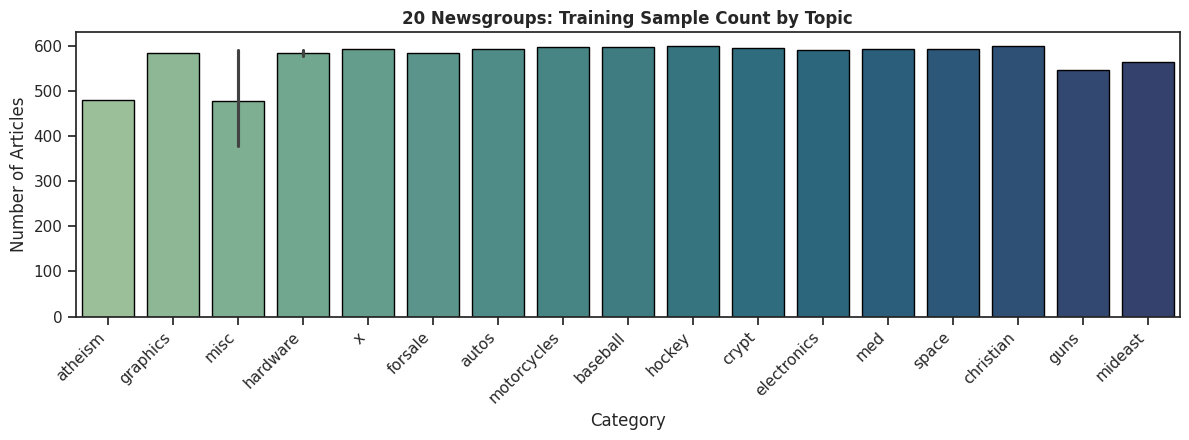

In [7]:
# 7. Optional Extension: Document length & vocabulary frequency analysis
doc_lengths = np.array([len(doc.split()) for doc in newsgroups_data.data])

print(">>> Document Word Count Distribution:")
print(f"  Min words:    {doc_lengths.min()}")
print(f"  Max words:    {doc_lengths.max():,}")
print(f"  Mean words:   {doc_lengths.mean():.1f}")
print(f"  Median words: {np.median(doc_lengths):.1f}")

# Visualize class distribution
plt.figure(figsize=(12, 4.5))
category_counts = pd.Series(newsgroups_data.target).value_counts().sort_index()
short_labels = [c.split('.')[-1] for c in newsgroups_data.target_names]

sns.barplot(x=short_labels, y=category_counts.values, palette="crest", edgecolor="black")
plt.title("20 Newsgroups: Training Sample Count by Topic", fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45, ha='right')
plt.show()


---
## Exercise 3 — Detecting and Handling Missing Values
**Dataset:** `employees.csv`

Real-world enterprise records often feature informal missingness markers (e.g. `'?'`, `'na'`, `'-'`, `'None'`) that require explicit harmonization prior to statistical imputation.


Dataset shape: (1000, 8)

Column datatypes & non-null counts:


,Dtype
First Name,str
Gender,str
Start Date,str
Last Login Time,str
Salary,int64
Bonus %,float64
Senior Management,object
Team,str


,Missing Count,Missing %
First Name,67,6.7
Gender,145,14.5
Start Date,0,0.0
Last Login Time,0,0.0
Salary,0,0.0
Bonus %,0,0.0
Senior Management,67,6.7
Team,43,4.3


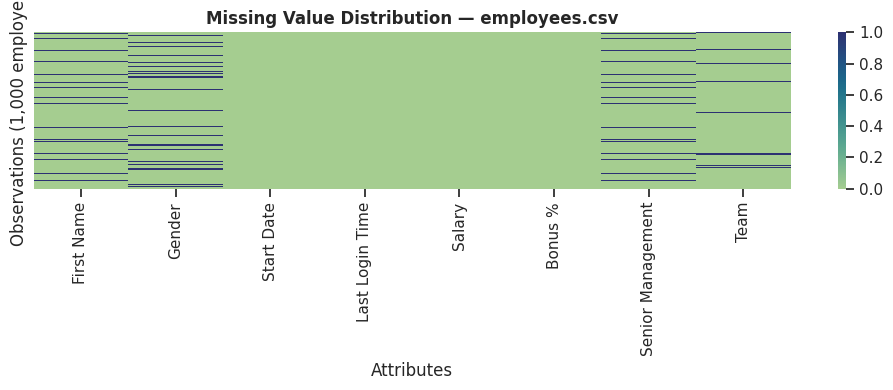

In [8]:
# 1. Load employees.csv and inspect structure
emp_file = os.path.join(DATA_PATH, "employees.csv")
df_emp = pd.read_csv(emp_file)

print(f"Dataset shape: {df_emp.shape}")
print("\nColumn datatypes & non-null counts:")
display(df_emp.dtypes.to_frame(name="Dtype"))

# 2. Count missing values per column
missing_initial = df_emp.isna().sum()
missing_pct = (df_emp.isna().mean() * 100).round(2)
display(pd.DataFrame({"Missing Count": missing_initial, "Missing %": missing_pct}))

# 3. Missing values heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(df_emp.isna(), cbar=True, cmap="crest", yticklabels=False)
plt.title("Missing Value Distribution — employees.csv", fontweight="bold")
plt.xlabel("Attributes")
plt.ylabel("Observations (1,000 employees)")
plt.show()


In [9]:
# 4. Create copy and append synthetic row with custom missing-value markers
df_emp_clean = df_emp.copy()

synthetic_sample = {
    "First Name": "-",
    "Gender": "na",
    "Start Date": "unknown",
    "Last Login Time": "?",
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": "None",
    "Team": "N/A"
}
df_emp_clean = pd.concat([df_emp_clean, pd.DataFrame([synthetic_sample])], ignore_index=True)

# 5. Recount missing values with default isna()
print(">>> Missing values count after inserting synthetic row:")
display(df_emp_clean.isna().sum().to_frame(name="Default isna() Count"))


>>> Missing values count after inserting synthetic row:


,Default isna() Count
First Name,67
Gender,145
Start Date,0
Last Login Time,0
Salary,1
Bonus %,1
Senior Management,67
Team,43


### Why does Pandas not automatically detect `'-'` and `'na'`?
By default, Pandas' `isna()` and CSV parsers only evaluate canonical null sentinels: `np.nan`, `None`, `<NA>`, and `NaT`. 

String literals such as `'-'`, `'na'`, `'?'`, and `'None'` are parsed as valid character strings (`str` object). To be treated as missing, non-standard sentinels must either be declared during file loading (`na_values=['-', 'na']`) or replaced explicitly with `np.nan`.


,Original Missing,Post-Replacement (Base 1000),Post-Imputation (Base 1000)
First Name,67,67,67
Gender,145,0,0
Start Date,0,0,0
Last Login Time,0,0,0
Salary,0,0,0
Bonus %,0,0,0
Senior Management,67,0,0
Team,43,0,0


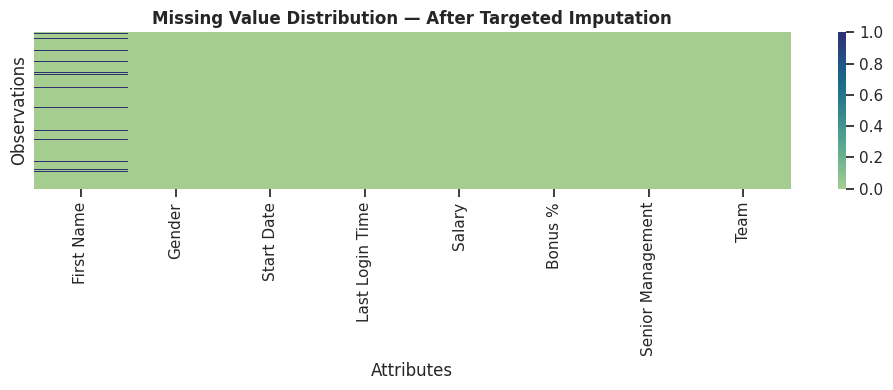

In [10]:
# 6. Harmonize all non-standard placeholders to np.nan
custom_sentinels = ["-", "na", "unknown", "?", "None", "N/A", "missing", "null"]
df_emp_clean.replace(custom_sentinels, np.nan, inplace=True)

# 7. Apply SimpleImputer with justified column strategies
# - Categorical features ('Gender', 'Senior Management', 'Team'): most_frequent mode
# - Continuous numerical features ('Salary', 'Bonus %'): median (robust to distribution skew)
# - Primary identifiers ('First Name', 'Start Date', 'Last Login Time'): NOT imputed

cat_cols = ["Gender", "Senior Management", "Team"]
num_cols = ["Salary", "Bonus %"]

mode_imputer = SimpleImputer(strategy="most_frequent")
df_emp_clean[cat_cols] = mode_imputer.fit_transform(df_emp_clean[cat_cols])

median_imputer = SimpleImputer(strategy="median")
df_emp_clean[num_cols] = median_imputer.fit_transform(df_emp_clean[num_cols])

# 8. Compare missing value statistics before and after imputation
comparison_report = pd.DataFrame({
    "Original Missing": missing_initial,
    "Post-Replacement (Base 1000)": df_emp_clean.iloc[:-1].isna().sum(),
    "Post-Imputation (Base 1000)": df_emp_clean.iloc[:-1].isna().sum()
})
display(comparison_report)

# Post-imputation heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(df_emp_clean.isna(), cbar=True, cmap="crest", yticklabels=False)
plt.title("Missing Value Distribution — After Targeted Imputation", fontweight="bold")
plt.xlabel("Attributes")
plt.ylabel("Observations")
plt.show()


### Inherent Limitations of Imputation:
1. **Variance Shrinkage:** Replacing unobserved entries with central point metrics (mean/median/mode) artificially reduces empirical feature variance $\sigma^2$.
2. **Covariance Distortion:** Single-variable imputation does not account for multidimensional correlations, attenuating true inter-variable associations.
3. **Underestimated Uncertainty:** Standard learning algorithms treat imputed figures with identical confidence as ground-truth observations, failing to propagate imputation error.
4. **Data Leakage in Pipelines:** Imputers must strictly be fitted on training sets only (`imputer.fit(X_train)`) and then applied to transform test splits (`imputer.transform(X_test)`). Fitting over full sets violates the train-test boundary.


---
## Exercise 4 — Feature Scaling, Binarization, and Categorical Encoding

### Part A. Scaling and Binarization
Matrix $\mathbf{X}$:
$$\mathbf{X} = \begin{pmatrix} 1 & -1 & 2 \\ 2 & 0 & 0 \\ 0 & 1 & -1 \end{pmatrix}$$


In [11]:
# Matrix definition
X_raw = np.array([
    [1.0, -1.0,  2.0],
    [2.0,  0.0,  0.0],
    [0.0,  1.0, -1.0]
])
features = ["Feature 1", "Feature 2", "Feature 3"]

# 1 & 2. Apply and display scaling methods
scalers_dict = {
    "StandardScaler (z-score)": StandardScaler().fit_transform(X_raw),
    "MinMaxScaler ([0, 1])": MinMaxScaler().fit_transform(X_raw),
    "MaxAbsScaler ([-1, 1])": MaxAbsScaler().fit_transform(X_raw),
    "RobustScaler (IQR)": RobustScaler().fit_transform(X_raw),
    "normalize (L2 norm)": normalize(X_raw, norm="l2")
}

print("=== Original Design Matrix ===")
display(pd.DataFrame(X_raw, columns=features))

for method_name, scaled_mat in scalers_dict.items():
    print(f"\n=== {method_name} ===")
    display(pd.DataFrame(scaled_mat, columns=features).round(4))

# 4. Binarization with explicit threshold
threshold_val = 0.0
binarizer = Binarizer(threshold=threshold_val)
X_binarized = binarizer.fit_transform(X_raw)

print(f"\n=== Binarized Matrix (Threshold = {threshold_val}: x > 0 -> 1, x <= 0 -> 0) ===")
display(pd.DataFrame(X_binarized, columns=features, dtype=int))


=== Original Design Matrix ===


,Feature 1,Feature 2,Feature 3
0,1.0,-1.0,2.0
1,2.0,0.0,0.0
2,0.0,1.0,-1.0



=== StandardScaler (z-score) ===


,Feature 1,Feature 2,Feature 3
0,0.0000,-1.2247,1.3363
1,1.2247,0.0000,-0.2673
2,-1.2247,1.2247,-1.0690



=== MinMaxScaler ([0, 1]) ===


,Feature 1,Feature 2,Feature 3
0,0.5,0.0,1.0000
1,1.0,0.5,0.3333
2,0.0,1.0,0.0000


... (4 outputs left out)


=== normalize (L2 norm) ===


,Feature 1,Feature 2,Feature 3
0,0.4082,-0.4082,0.8165
1,1.0000,0.0000,0.0000
2,0.0000,0.7071,-0.7071



=== Binarized Matrix (Threshold = 0.0: x > 0 -> 1, x <= 0 -> 0) ===


,Feature 1,Feature 2,Feature 3
0,1,0,1
1,1,0,0
2,0,1,0


### 3. Scaling vs. Normalization:
- **Feature Scaling (Column-wise):** `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`, and `RobustScaler` compute column statistics along feature dimensions across all samples. Their goal is to harmonize coordinate axes so that features with large numerical magnitudes do not dominate objective functions.
- **Sample Normalization (Row-wise):** `normalize` operates horizontally across features for each individual observation vector, projecting it onto a unit hypersphere ($\|\mathbf{x}\|_2 = 1$). It is used in directional clustering, text mining, and cosine similarity.

> ### Discussion: Why does scaling matter for KNN, SVMs, and Gradient-based models? Is it needed for Decision Trees?
> - **K-Nearest Neighbors (KNN):** Distance-based models compute Euclidean metric $d(\mathbf{u}, \mathbf{v}) = \sqrt{\sum_j (u_j - v_j)^2}$. An unscaled attribute on scale $[0, 1000]$ would overpower an attribute on scale $[0, 1]$, rendering the latter statistically invisible.
> - **Support Vector Machines (SVM):** Margin maximization ($2 / \|\mathbf{w}\|$) and radial basis kernels ($K(\mathbf{u}, \mathbf{v}) = \exp(-\gamma \|\mathbf{u} - \mathbf{v}\|^2$) assume isotropic feature spaces. Unscaled variables distort the maximum-margin hyperplane.
> - **Gradient Descent:** Unequal feature scales produce steep, elongated elliptical error surfaces (high condition number). Gradients oscillate perpendicularly rather than descending directly toward the optimum, requiring inefficiently small learning rates.
> - **Decision Trees:** Decision trees evaluate orthogonal, axis-aligned splits on single features ($x_j \le \theta$). Because monotonic transformations preserve feature ordering, **decision trees are scale-invariant**; scaling has zero impact on tree splits or model performance.


In [12]:
# Part B: Categorical Dataset
df_cat = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target": ["US", "France", "Japan", "Algeria"]
})
print(">>> Categorical Input Dataset:")
display(df_cat)

# 1. OrdinalEncoder on features
ordinal_transformer = OrdinalEncoder()
features_ordinal = ordinal_transformer.fit_transform(df_cat[["Feature 1", "Feature 2", "Feature 3"]])
print("\n>>> OrdinalEncoded Input Features:")
display(pd.DataFrame(features_ordinal, columns=["Feature 1", "Feature 2", "Feature 3"], dtype=int))

print("\nLearned Categories (encoder.categories_):")
for col_name, cats in zip(["Feature 1", "Feature 2", "Feature 3"], ordinal_transformer.categories_):
    print(f"  {col_name}: {list(cats)}")

# 2. LabelEncoder on target
label_transformer = LabelEncoder()
target_labels = label_transformer.fit_transform(df_cat["Target"])
print("\n>>> LabelEncoded Target Variable:")
for code, class_name in enumerate(label_transformer.classes_):
    print(f"  Class '{class_name}' -> Code {code}")
print(f"Target codes: {target_labels}")

# 3. OneHotEncoder on target
ohe_transformer = OneHotEncoder(sparse_output=False)
target_ohe = ohe_transformer.fit_transform(df_cat[["Target"]])
print("\n>>> OneHotEncoded Target (Orthogonal Binary Matrix):")
display(pd.DataFrame(target_ohe, columns=ohe_transformer.categories_[0], dtype=int))


>>> Categorical Input Dataset:


,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria



>>> OrdinalEncoded Input Features:


,Feature 1,Feature 2,Feature 3
0,1,3,2
1,0,2,2
2,0,1,1
3,1,0,0



Learned Categories (encoder.categories_):
  Feature 1: ['female', 'male']
  Feature 2: ['from Africa', 'from Asia', 'from Europe', 'from US']
  Feature 3: ['uses Chrome', 'uses Firefox', 'uses Safari']

>>> LabelEncoded Target Variable:
  Class 'Algeria' -> Code 0
  Class 'France' -> Code 1
  Class 'Japan' -> Code 2
  Class 'US' -> Code 3
Target codes: [3 1 2 0]

>>> OneHotEncoded Target (Orthogonal Binary Matrix):


,Algeria,France,Japan,US
0,0,0,0,1
1,0,1,0,0
2,0,0,1,0
3,1,0,0,0


### 4. Why One-Hot Encoding is superior to Ordinal Codes for Nominal Features:
- **The Metric Bias of Ordinal Codes:** Ordinal encoding maps discrete nominal categories to integer scalars ($0, 1, 2, \dots$). This implicitly imposes an artificial ordering and metric distance:
  $$\text{Algeria}(0) < \text{France}(1) < \text{Japan}(2) < \text{US}(3)$$
  $$\|\text{US} - \text{Algeria}\| = 3 \quad \text{vs.} \quad \|\text{France} - \text{Algeria}\| = 1$$
  Linear models and neural networks will interpret these numbers as continuous quantities, learning spurious weights.
- **Geometric Orthogonality of One-Hot Vectors:** One-hot encoding assigns each category to a distinct basis vector $\mathbf{e}_k$ in $\mathbb{R}^K$. Every category pair is mutually orthogonal and equidistant:
  $$\|\mathbf{e}_i - \mathbf{e}_j\|_2 = \sqrt{1^2 + (-1)^2} = \sqrt{2} \quad \forall i \ne j$$
  This eliminates false inductive bias and allows linear classifiers to separate nominal categories with complete geometric symmetry.


---
## Synthesis: Preprocessing Best Practices Taxonomy

| Data Modality | Typical Pipeline Operations | Recommended Scikit-Learn Classes | Critical Failure Modes to Avoid |
| :--- | :--- | :--- | :--- |
| **Numerical Data** | • Outlier detection & winsorization<br>• Missing value imputation (median)<br>• Feature scaling (StandardScaler / RobustScaler) | `SimpleImputer(strategy='median')`<br>`StandardScaler`<br>`RobustScaler` | **Data Leakage:** Fitting scalers or imputers across the entire dataset instead of strictly on the training partition. |
| **Categorical Data** | • Mode imputation<br>• Ordinal encoding for intrinsically ordered levels<br>• One-hot encoding for nominal categories | `SimpleImputer(strategy='most_frequent')`<br>`OneHotEncoder(handle_unknown='ignore')`<br>`OrdinalEncoder` | Imposing linear ordering on nominal classes with integer encoding; high-cardinality dimensionality explosions. |
| **Text Data** | • Encoding normalization (UTF-8)<br>• Tokenization & whitespace cleaning<br>• Vocabulary frequency analysis & vectorization | `CountVectorizer`<br>`TfidfVectorizer`<br>`fetch_20newsgroups` | Out-of-vocabulary terms during inference; leaking test document terms into global inverse-document frequency (IDF) matrices. |
